# 01 — ETL secuencial de datos abiertos de COVID-19 e influenza (México)

**Responsable:** Integrante 1 — preparación de datos y línea base secuencial  
**Proyecto:** Pipeline ETL para cómputo de alto rendimiento

## Objetivo
Construir un proceso ETL secuencial reproducible: extraer el CSV del ZIP, explorar y limpiar los registros, generar variables derivadas y resúmenes, validar la salida y exportar los resultados que utilizarán los integrantes responsables de Docker/Kubernetes y del análisis de rendimiento.

## Alcance de esta parte
Esta entrega cubre únicamente la versión secuencial. No configura Docker ni Kubernetes y no realiza la comparación de speedup/eficiencia, que corresponde a los demás integrantes.

## Consideraciones sobre los datos
- Se conserva el valor original de las variables categóricas codificadas. No se traducen códigos como `1`, `2`, `6`, `7`, `97`, `99` o `998` sin consultar el diccionario oficial que acompaña a la fuente.
- El valor `9999-99-99` en `FECHA_DEF` se interpreta como fecha no disponible.
- No se eliminan filas por tener campos clínicos o demográficos incompletos.
- Las filas se eliminan únicamente si son duplicados exactos o si repiten `ID_REGISTRO`; el notebook informa cuántas se retiran.
- Las conclusiones y los tiempos se completan con los valores obtenidos al ejecutar el notebook, no con cifras supuestas.


## 1. Preparación del entorno

Coloca el archivo `datos_abiertos_influenza_covid19.zip` en la misma carpeta que este notebook. El código crea las carpetas `datos/` y `resultados/` automáticamente.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from time import perf_counter
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)

RUTA_ZIP = Path("datos_abiertos_influenza_covid19.zip")
CARPETA_DATOS = Path("datos")
CARPETA_RESULTADOS = Path("resultados_etl_persona1")
CARPETA_DATOS.mkdir(exist_ok=True)
CARPETA_RESULTADOS.mkdir(exist_ok=True)


## 2. Extracción del archivo (E de ETL)

Se localiza el CSV dentro del ZIP y se extrae a la carpeta `datos/`. Se valida que el archivo comprimido exista y contenga al menos un CSV.

In [2]:
if not RUTA_ZIP.exists():
    raise FileNotFoundError(
        f"No se encontró {RUTA_ZIP.resolve()}. "
        "Descarga el ZIP y colócalo junto al notebook."
    )

with ZipFile(RUTA_ZIP, "r") as archivo_zip:
    archivos_csv = [n for n in archivo_zip.namelist() if n.lower().endswith(".csv")]
    if not archivos_csv:
        raise FileNotFoundError("El ZIP no contiene archivos CSV.")
    nombre_csv = archivos_csv[0]
    ruta_csv = CARPETA_DATOS / Path(nombre_csv).name

    # Si el CSV ya fue extraído anteriormente, se reutiliza.
    if not ruta_csv.exists():
        with archivo_zip.open(nombre_csv) as origen, open(ruta_csv, "wb") as destino:
            destino.write(origen.read())

print("CSV disponible en:", ruta_csv.resolve())
print(f"Tamaño del CSV: {ruta_csv.stat().st_size / (1024**2):.2f} MB")

CSV disponible en: /home/pati/Downloads/datos/COVID19MEXICO.csv
Tamaño del CSV: 17.43 MB


## 3. Carga de datos (E de ETL)

Se intenta primero UTF-8, que conserva correctamente caracteres acentuados; si el archivo no está codificado en UTF-8, se intenta `latin-1`. La lectura se realiza una sola vez para crear el conjunto original de referencia.

In [3]:
def cargar_csv(ruta):
    """Carga el CSV e intenta codificaciones comunes."""
    for codificacion in ("utf-8-sig", "latin-1"):
        try:
            return pd.read_csv(ruta, encoding=codificacion, low_memory=False)
        except UnicodeDecodeError:
            continue
    raise UnicodeError("No fue posible decodificar el archivo CSV.")

df_original = cargar_csv(ruta_csv)

print(f"Registros de entrada: {len(df_original):,}")
print(f"Columnas de entrada: {len(df_original.columns)}")
display(df_original.head())


Registros de entrada: 108,733
Columnas de entrada: 42


,FECHA_ACTUALIZACION,ID_REGISTRO,ORIGEN,SECTOR,ENTIDAD_UM,SEXO,ENTIDAD_NAC,ENTIDAD_RES,MUNICIPIO_RES,TIPO_PACIENTE,FECHA_INGRESO,FECHA_SINTOMAS,FECHA_DEF,INTUBADO,NEUMONIA,EDAD,NACIONALIDAD,EMBARAZO,HABLA_LENGUA_INDIG,INDIGENA,DIABETES,EPOC,ASMA,INMUSUPR,HIPERTENSION,OTRA_COM,CARDIOVASCULAR,OBESIDAD,RENAL_CRONICA,TABAQUISMO,OTRO_CASO,TOMA_MUESTRA_LAB,RESULTADO_PCR,RESULTADO_PCR_COINFECCION,TOMA_MUESTRA_ANTIGENO,RESULTADO_ANTIGENO,CLASIFICACION_FINAL_COVID,CLASIFICACION_FINAL_FLU,MIGRANTE,PAIS_NACIONALIDAD,PAIS_ORIGEN,UCI
0,2026-11-02,g829cab,1,12,11,2,11,11,15,1,2026-01-02,2026-01-01,9999-99-99,97,2,33,1,97,2,2,2,2,2,2,2,2,2,2,2,2,2,2,997,997,2,97,6,6,99,México,97,97
1,2026-11-02,gc633cc,1,8,9,2,7,9,12,1,2026-01-02,2026-01-01,9999-99-99,97,2,58,1,97,2,2,2,2,2,2,1,2,2,2,2,2,2,2,997,997,2,97,6,6,99,México,97,97
2,2026-11-02,gad762a,1,4,30,2,30,30,87,2,2026-01-02,2026-01-02,9999-99-99,2,2,1,1,97,2,2,2,2,2,2,2,2,2,2,2,2,1,1,3,998,2,97,7,3,99,México,97,2
3,2026-11-02,gd88222,1,8,9,2,9,9,10,1,2026-01-02,2026-01-01,9999-99-99,97,2,45,1,97,2,2,2,2,2,2,2,2,2,2,2,2,2,2,997,997,2,97,6,6,99,México,97,97
4,2026-11-02,g8447ee,1,4,9,2,9,9,6,2,2026-01-02,2026-01-02,9999-99-99,2,2,2,1,97,2,2,2,2,2,2,2,2,2,2,2,2,2,2,997,997,2,97,6,6,99,México,97,2


## 4. Descripción y diccionario de variables

El archivo contiene observaciones de vigilancia epidemiológica. Las variables se pueden agrupar por tema. La descripción siguiente es orientativa según el nombre de las columnas; los significados exactos de los códigos deben confirmarse en el diccionario oficial de la base.

| Grupo | Variables incluidas | Uso dentro del análisis |
|---|---|---|
| Identificación y fuente | `ID_REGISTRO`, `ORIGEN`, `SECTOR` | Identificar registros y procedencia |
| Ubicación | `ENTIDAD_UM`, `ENTIDAD_NAC`, `ENTIDAD_RES`, `MUNICIPIO_RES`, `PAIS_NACIONALIDAD`, `PAIS_ORIGEN` | Distribución geográfica |
| Datos demográficos | `SEXO`, `EDAD`, `NACIONALIDAD`, `EMBARAZO`, `INDIGENA`, `HABLA_LENGUA_INDIG`, `MIGRANTE` | Caracterización de personas |
| Atención y evolución | `TIPO_PACIENTE`, `INTUBADO`, `NEUMONIA`, `UCI`, `FECHA_INGRESO`, `FECHA_DEF` | Atención hospitalaria y evolución |
| Síntomas y comorbilidades | `FECHA_SINTOMAS`, `DIABETES`, `EPOC`, `ASMA`, `INMUSUPR`, `HIPERTENSION`, `OBESIDAD`, `RENAL_CRONICA`, `TABAQUISMO`, entre otras | Antecedentes y factores reportados |
| Pruebas y clasificación | `TOMA_MUESTRA_LAB`, `RESULTADO_PCR`, `RESULTADO_PCR_COINFECCION`, `TOMA_MUESTRA_ANTIGENO`, `RESULTADO_ANTIGENO`, `CLASIFICACION_FINAL_COVID`, `CLASIFICACION_FINAL_FLU` | Información de pruebas y clasificación |

La siguiente celda verifica las columnas reales del archivo, ya que el esquema puede cambiar entre versiones.

In [4]:
print("Número de columnas:", len(df_original.columns))
display(pd.DataFrame({
    "columna": df_original.columns,
    "tipo": [str(t) for t in df_original.dtypes],
    "valores_no_nulos": [int(df_original[c].notna().sum()) for c in df_original.columns],
    "valores_nulos": [int(df_original[c].isna().sum()) for c in df_original.columns],
}))


Número de columnas: 42


,columna,tipo,valores_no_nulos,valores_nulos
0,FECHA_ACTUALIZACION,str,108733,0
1,ID_REGISTRO,str,108733,0
2,ORIGEN,int64,108733,0
3,SECTOR,int64,108733,0
4,ENTIDAD_UM,int64,108733,0
5,SEXO,int64,108733,0
6,ENTIDAD_NAC,int64,108733,0
7,ENTIDAD_RES,int64,108733,0
8,MUNICIPIO_RES,int64,108733,0
9,TIPO_PACIENTE,int64,108733,0


## 5. Análisis exploratorio inicial

Antes de limpiar, se examinan dimensiones, tipos de datos, nulos, duplicados y distribución de variables importantes. Estas salidas documentan el estado inicial del conjunto.

In [5]:
print("Dimensiones:", df_original.shape)
print("Duplicados exactos:", int(df_original.duplicated().sum()))
if "ID_REGISTRO" in df_original.columns:
    print("ID_REGISTRO duplicados:", int(df_original["ID_REGISTRO"].duplicated().sum()))

tabla_nulos = (
    df_original.isna().sum()
    .rename("cantidad_nulos")
    .to_frame()
    .assign(porcentaje=lambda x: (x["cantidad_nulos"] / len(df_original) * 100).round(2))
    .sort_values("cantidad_nulos", ascending=False)
)
display(tabla_nulos)

if "EDAD" in df_original.columns:
    display(df_original["EDAD"].describe().to_frame())


Dimensiones: (108733, 42)
Duplicados exactos: 0
ID_REGISTRO duplicados: 0


,cantidad_nulos,porcentaje
FECHA_ACTUALIZACION,0,0.0
ID_REGISTRO,0,0.0
ORIGEN,0,0.0
SECTOR,0,0.0
ENTIDAD_UM,0,0.0
SEXO,0,0.0
ENTIDAD_NAC,0,0.0
ENTIDAD_RES,0,0.0
MUNICIPIO_RES,0,0.0
TIPO_PACIENTE,0,0.0


,EDAD
count,108733.000000
mean,34.212705
std,26.708780
min,0.000000
25%,8.000000
50%,31.000000
75%,55.000000
max,111.000000


### 5.1 Visualización exploratoria

Las gráficas muestran distribuciones de las variables disponibles. Para variables categóricas codificadas se presentan los códigos sin asignarles etiquetas clínicas no verificadas.

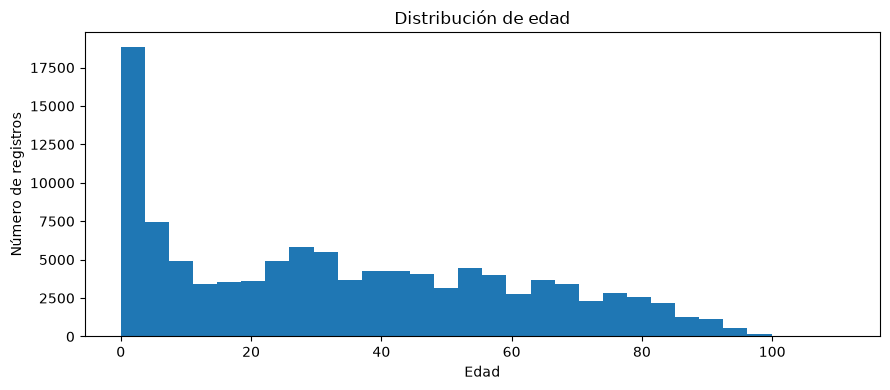

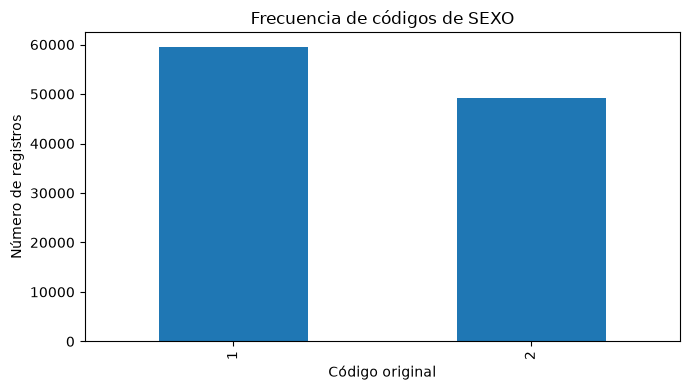

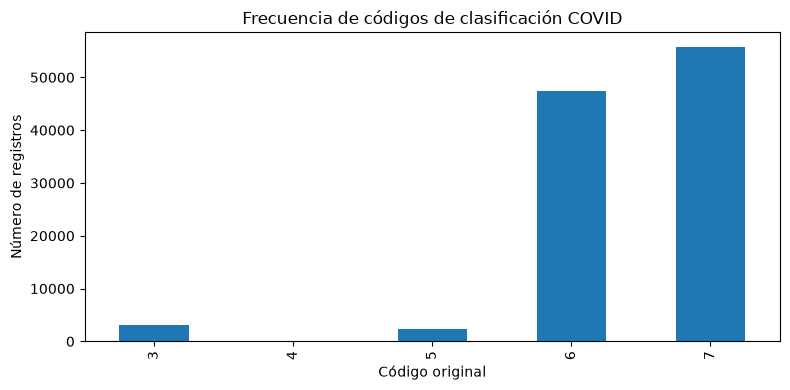

In [6]:
# Distribución de edad
if "EDAD" in df_original.columns:
    edades = pd.to_numeric(df_original["EDAD"], errors="coerce").dropna()
    plt.figure(figsize=(9, 4))
    plt.hist(edades, bins=30)
    plt.title("Distribución de edad")
    plt.xlabel("Edad")
    plt.ylabel("Número de registros")
    plt.tight_layout()
    plt.show()

# Frecuencia de sexo (códigos originales)
if "SEXO" in df_original.columns:
    conteo_sexo = df_original["SEXO"].value_counts(dropna=False).sort_index()
    plt.figure(figsize=(7, 4))
    conteo_sexo.plot(kind="bar")
    plt.title("Frecuencia de códigos de SEXO")
    plt.xlabel("Código original")
    plt.ylabel("Número de registros")
    plt.tight_layout()
    plt.show()

# Frecuencia de clasificación final COVID (códigos originales)
if "CLASIFICACION_FINAL_COVID" in df_original.columns:
    conteo_clasif = df_original["CLASIFICACION_FINAL_COVID"].value_counts(dropna=False).sort_index()
    plt.figure(figsize=(8, 4))
    conteo_clasif.plot(kind="bar")
    plt.title("Frecuencia de códigos de clasificación COVID")
    plt.xlabel("Código original")
    plt.ylabel("Número de registros")
    plt.tight_layout()
    plt.show()


## 6. Reglas de limpieza y transformación (T de ETL)

Las reglas se aplican de forma secuencial y quedan documentadas:

1. Normalizar encabezados: quitar espacios exteriores y convertir a mayúsculas.
2. Eliminar duplicados exactos.
3. Si existe `ID_REGISTRO`, conservar la primera fila de cada identificador.
4. Convertir las columnas de fecha reconocidas a `datetime`; fechas no interpretables se convierten en `NaT`.
5. Reemplazar el marcador `9999-99-99` por dato no disponible en fechas.
6. Convertir `EDAD` a valor numérico; valores fuera de 0–120 se consideran inválidos y se marcan como `NaN`, sin eliminar la fila.
7. Quitar espacios exteriores en columnas de texto.

No se eliminan registros por valores faltantes de variables clínicas, ni se recodifican códigos categóricos sin consultar el diccionario oficial.

In [8]:
COLUMNAS_FECHA = [
    "FECHA_ACTUALIZACION",
    "FECHA_INGRESO",
    "FECHA_SINTOMAS",
    "FECHA_DEF",
]

def transformar_datos(df):
    """Aplica la limpieza y transformación de forma secuencial."""
    datos = df.copy()
    filas_iniciales = len(datos)

    # 1. Normalizar encabezados
    datos.columns = datos.columns.str.strip().str.upper()

    # 2. Eliminar duplicados exactos
    duplicados_exactos = int(datos.duplicated().sum())
    datos = datos.drop_duplicates()

    # 3. Resolver identificadores repetidos
    duplicados_id = 0
    if "ID_REGISTRO" in datos.columns:
        duplicados_id = int(datos["ID_REGISTRO"].duplicated().sum())
        datos = datos.drop_duplicates(subset=["ID_REGISTRO"], keep="first")

    # 4 y 5. Convertir fechas y tratar el marcador de fecha desconocida
    for columna in COLUMNAS_FECHA:
        if columna in datos.columns:
            fechas = datos[columna].astype("string").str.strip()
            fechas = fechas.replace({"9999-99-99": pd.NA, "": pd.NA})
            datos[columna] = pd.to_datetime(fechas, errors="coerce")

    # 6. Validar edad sin descartar el registro completo
    edades_invalidas = 0
    if "EDAD" in datos.columns:
        datos["EDAD"] = pd.to_numeric(datos["EDAD"], errors="coerce")
        mascara_edad_invalida = datos["EDAD"].notna() & ~datos["EDAD"].between(0, 120)
        edades_invalidas = int(mascara_edad_invalida.sum())
        datos.loc[mascara_edad_invalida, "EDAD"] = np.nan

    # 7. Quitar espacios exteriores en campos de texto
    columnas_texto = datos.select_dtypes(include=["object", "string"]).columns
    for columna in columnas_texto:
        datos[columna] = datos[columna].astype("string").str.strip()

    auditoria = {
        "filas_entrada": filas_iniciales,
        "duplicados_exactos_eliminados": duplicados_exactos,
        "duplicados_id_eliminados": duplicados_id,
        "edades_invalidas_convertidas_a_nulo": edades_invalidas,
        "filas_salida": len(datos),
    }
    return datos, auditoria


## 7. Ejecución del ETL secuencial y medición del tiempo

Se mide la función completa de transformación sobre los datos ya cargados en memoria. La lectura del CSV y la exportación se reportan por separado, para que el equipo compare el mismo alcance de trabajo en las implementaciones paralelas.

In [9]:
inicio_etl = perf_counter()
df_limpio, auditoria_limpieza = transformar_datos(df_original)
tiempo_etl = perf_counter() - inicio_etl

print(f"Tiempo de transformación secuencial: {tiempo_etl:.6f} segundos")
display(pd.DataFrame([auditoria_limpieza]))
print("Dimensiones antes:", df_original.shape)
print("Dimensiones después:", df_limpio.shape)


Tiempo de transformación secuencial: 0.535867 segundos


,filas_entrada,duplicados_exactos_eliminados,duplicados_id_eliminados,edades_invalidas_convertidas_a_nulo,filas_salida
0,108733,0,0,0,108733


Dimensiones antes: (108733, 42)
Dimensiones después: (108733, 42)


## 8. Validación de resultados

Se realizan comprobaciones de integridad: unicidad de identificadores, rango de edad, tipo de las fechas y consistencia del número de filas. Estas pruebas permiten verificar que la transformación no haya alterado accidentalmente la estructura.

In [10]:
validaciones = {}

validaciones["columnas_sin_duplicados"] = df_limpio.columns.is_unique
if "ID_REGISTRO" in df_limpio.columns:
    validaciones["id_registro_unico"] = df_limpio["ID_REGISTRO"].is_unique
if "EDAD" in df_limpio.columns:
    validaciones["edades_no_nulas_en_rango_0_120"] = bool(
        df_limpio["EDAD"].dropna().between(0, 120).all()
    )
for columna in COLUMNAS_FECHA:
    if columna in df_limpio.columns:
        validaciones[f"{columna}_es_fecha"] = pd.api.types.is_datetime64_any_dtype(df_limpio[columna])

validaciones["filas_salida_no_mayores_que_entrada"] = len(df_limpio) <= len(df_original)

display(pd.Series(validaciones, name="resultado").to_frame())
assert all(validaciones.values()), "Una o más validaciones no se cumplieron."
print("Todas las validaciones se cumplieron.")


,resultado
columnas_sin_duplicados,True
id_registro_unico,True
edades_no_nulas_en_rango_0_120,True
FECHA_ACTUALIZACION_es_fecha,True
FECHA_INGRESO_es_fecha,True
FECHA_SINTOMAS_es_fecha,True
FECHA_DEF_es_fecha,True
filas_salida_no_mayores_que_entrada,True


Todas las validaciones se cumplieron.


## 9. Agregaciones descriptivas

Se crean resúmenes sencillos a partir de los datos limpios. Los códigos de clasificación permanecen como códigos originales; para darles significado clínico se debe consultar el catálogo oficial.

In [11]:
def resumen_frecuencias(df, columna, nombre_codigo):
    if columna not in df.columns:
        return pd.DataFrame(columns=[nombre_codigo, "registros"])
    return (
        df[columna].value_counts(dropna=False).sort_index()
        .rename_axis(nombre_codigo)
        .reset_index(name="registros")
    )

resumen_covid = resumen_frecuencias(
    df_limpio, "CLASIFICACION_FINAL_COVID", "codigo_clasificacion_covid"
)
resumen_influenza = resumen_frecuencias(
    df_limpio, "CLASIFICACION_FINAL_FLU", "codigo_clasificacion_influenza"
)

display(resumen_covid)
display(resumen_influenza)


,codigo_clasificacion_covid,registros
0,3,3079
1,4,32
2,5,2399
3,6,47479
4,7,55744


,codigo_clasificacion_influenza,registros
0,3,7873
1,4,32
2,5,2399
3,6,47479
4,7,50950


In [11]:
# Conteo mensual de registros por fecha de ingreso
if "FECHA_INGRESO" in df_limpio.columns:
    mes_ingreso = df_limpio["FECHA_INGRESO"].dt.to_period("M").astype("string")
    resumen_mensual = (
        mes_ingreso.value_counts(dropna=False)
        .rename_axis("mes_ingreso")
        .reset_index(name="registros")
        .sort_values("mes_ingreso")
    )
else:
    resumen_mensual = pd.DataFrame(columns=["mes_ingreso", "registros"])

display(resumen_mensual)


,mes_ingreso,registros
0,2026-01,18154
1,2026-02,17064
2,2026-03,13289
8,2026-04,7441
9,2026-05,6933
7,2026-06,7514
5,2026-07,9761
6,2026-08,7530
4,2026-09,10017
3,2026-10,10976


## 10. Carga y exportación (L de ETL)

Se exporta el conjunto limpio y las tablas agregadas. Estos archivos son los productos que deben compartirse con los integrantes que desarrollen las versiones paralelas. Se guarda el CSV limpio con fechas en formato ISO y codificación UTF-8.

In [12]:
archivos_salida = {
    "COVID19MEXICO_limpio.csv": df_limpio,
    "resumen_clasificacion_covid.csv": resumen_covid,
    "resumen_clasificacion_influenza.csv": resumen_influenza,
    "resumen_mensual_ingresos.csv": resumen_mensual,
}

for nombre, tabla in archivos_salida.items():
    ruta_salida = CARPETA_RESULTADOS / nombre
    tabla.to_csv(ruta_salida, index=False, encoding="utf-8-sig")
    print(f"{ruta_salida}: {ruta_salida.stat().st_size / (1024**2):.2f} MB")


resultados_etl_persona1/COVID19MEXICO_limpio.csv: 14.04 MB
resultados_etl_persona1/resumen_clasificacion_covid.csv: 0.00 MB
resultados_etl_persona1/resumen_clasificacion_influenza.csv: 0.00 MB
resultados_etl_persona1/resumen_mensual_ingresos.csv: 0.00 MB


## 11. Repeticiones de rendimiento de la versión secuencial

Para reducir el efecto de variaciones ocasionales, se ejecuta la transformación varias veces. La primera ejecución se conserva aparte como medición inicial; la tabla de repeticiones reporta media, mediana y desviación estándar. El integrante de rendimiento debe comparar con el mismo número de repeticiones y el mismo alcance de medición.

In [13]:
NUM_REPETICIONES = 5
tiempos = []
for numero in range(1, NUM_REPETICIONES + 1):
    inicio = perf_counter()
    resultado_prueba, _ = transformar_datos(df_original)
    duracion = perf_counter() - inicio
    tiempos.append(duracion)
    print(f"Repetición {numero}: {duracion:.6f} s")

# Verificar que la salida repetida coincide con la transformación principal
assert resultado_prueba.shape == df_limpio.shape
assert resultado_prueba.equals(df_limpio)

metricas_rendimiento = pd.DataFrame([{
    "implementacion": "ETL_secuencial",
    "registros_entrada": len(df_original),
    "registros_salida": len(df_limpio),
    "columnas_salida": len(df_limpio.columns),
    "repeticiones": NUM_REPETICIONES,
    "tiempo_inicial_segundos": tiempo_etl,
    "tiempo_promedio_segundos": float(np.mean(tiempos)),
    "tiempo_mediano_segundos": float(np.median(tiempos)),
    "desviacion_estandar_segundos": float(np.std(tiempos, ddof=1)),
}])

display(metricas_rendimiento)
metricas_rendimiento.to_csv(
    CARPETA_RESULTADOS / "tiempo_etl_secuencial.csv",
    index=False,
    encoding="utf-8-sig"
)


Repetición 1: 0.444674 s


Repetición 2: 0.445945 s


Repetición 3: 0.451153 s


Repetición 4: 0.438910 s


Repetición 5: 0.444187 s


,implementacion,registros_entrada,registros_salida,columnas_salida,repeticiones,tiempo_inicial_segundos,tiempo_promedio_segundos,tiempo_mediano_segundos,desviacion_estandar_segundos
0,ETL_secuencial,108733,108733,42,5,0.444855,0.444974,0.444674,0.004376


## 12. Conclusiones

1. El conjunto de datos original contiene **108,733 registros y 42 variables**, correspondientes a información epidemiológica de COVID-19 e influenza en México.

2. Durante el proceso de limpieza se identificaron **0 registros duplicados exactos y 0 identificadores repetidos**. Por lo tanto, no fue necesario eliminar registros y se conservaron los **108,733 registros originales**.

3. Se realizaron transformaciones en las columnas de fecha para convertirlas a un formato adecuado para su análisis. Además, se trataron los marcadores de fechas no disponibles, como `9999-99-99`, convirtiéndolos en valores nulos (`NaT`). También se verificaron los valores de edad, sin encontrar registros fuera del rango establecido de 0 a 120 años.

4. Se realizaron las validaciones correspondientes para comprobar la integridad de los datos. **Todas las validaciones se cumplieron correctamente**. Posteriormente, se generaron archivos CSV con los datos limpios y los resúmenes de clasificación de COVID-19, influenza y registros mensuales.

5. El tiempo promedio de transformación secuencial fue de **0.444974 segundos**, con una desviación estándar de **0.004376 segundos**, obtenidos mediante **5 repeticiones**. Estos resultados permiten establecer una referencia inicial del rendimiento del procesamiento secuencial.

6. Finalmente, se implementó correctamente el pipeline ETL secuencial, realizando las etapas de extracción, transformación y carga de datos. Esta implementación constituye la **línea base para comparar el rendimiento de las versiones paralelas desarrolladas con Docker y Kubernetes**, permitiendo evaluar posteriormente las mejoras en los tiempos de procesamiento.

